ANALYTICAL CLASS-E DESIGN
------------------------------------------------------------
KR = 0.576801, KC = 0.183601, KL = 1.152494, phi = 147.518°
Ropt = 8.2229 Ω, Csh = 253.830 pF, L1 = 107.735 nH, L2 = 280.439 nH, C2 = 460.835 pF
IDC Sokal = 340.206 mA, IR Sokal = 633.497 mA, P_gate = 8.050 mW

TEMPERATURE MODEL (Fig 8)
------------------------------------------------------------
RON typical @ 75°C = 0.5200 Ω, RON maximum @ 75°C = 0.7150 Ω
Model equiv C_ER = 9.500 pF

Running baseline cases A, C, E...

Running SLSQP optimization for Tuned case (T)...


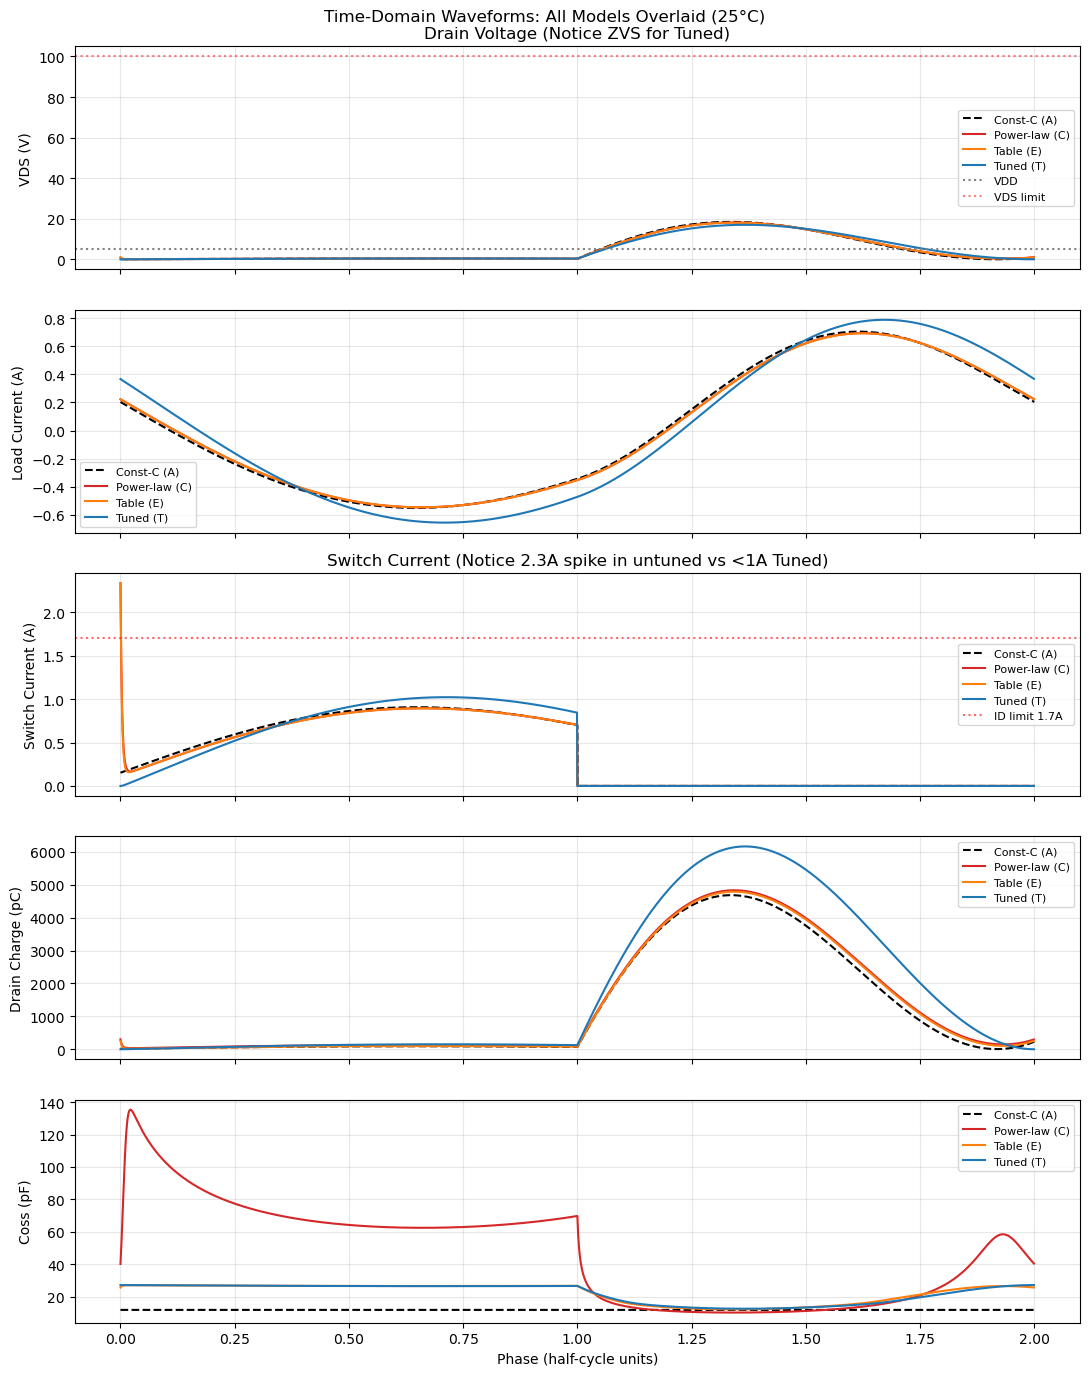

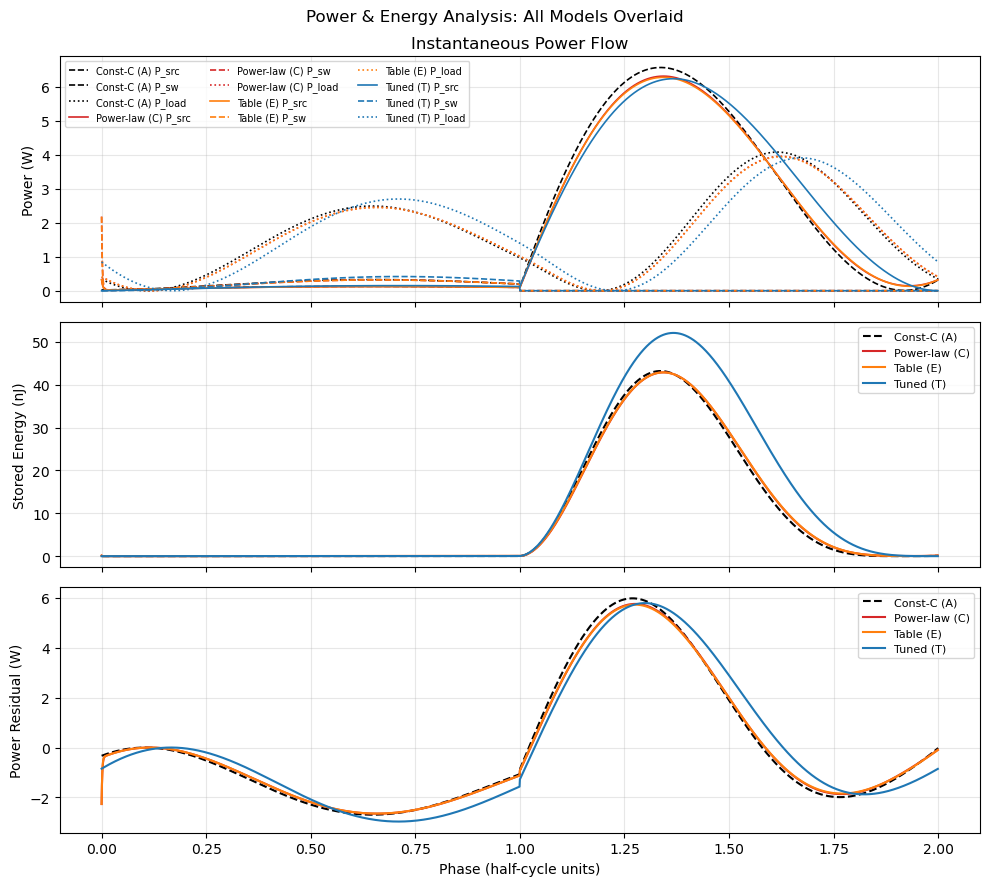


### SOKAL vs SIMULATED (Case A)
--------------------------------------------------------------------------------
Metric                    |  Ideal Sokal |   Simulated (A)
--------------------------------------------------------------------------------
Peak drain voltage (V)    |       17.276 |          18.450
Drain voltage @ turn-on   |        0.000 |           0.901
Peak load current (A)     |        0.633 |           0.704
Load current @ turn-on    |        0.340 |           0.204

### FULL DIAGNOSTICS TABLE (ALL VARIANTS)

Tag         Model  Ron (Ω)  Cext (pF)  Ropt (Ω)  Vturn_on (V)  i_sw_pk (A)  P_load (mW)  P_Ron (mW)  P_ZVS (mW)  P_gate (mW)  P_in (mW)  Pout_err (mW)  η_sys (%)  bal (mW)  E_turn (nJ)
  A   Const-C (A)      0.4    241.830     8.223         0.901        0.906     1615.931     109.082       1.442         8.05   1726.266        -34.069     93.174    -0.189        0.103
  C Power-law (C)      0.4    247.330     8.223         0.934        2.335     1581.541     106.

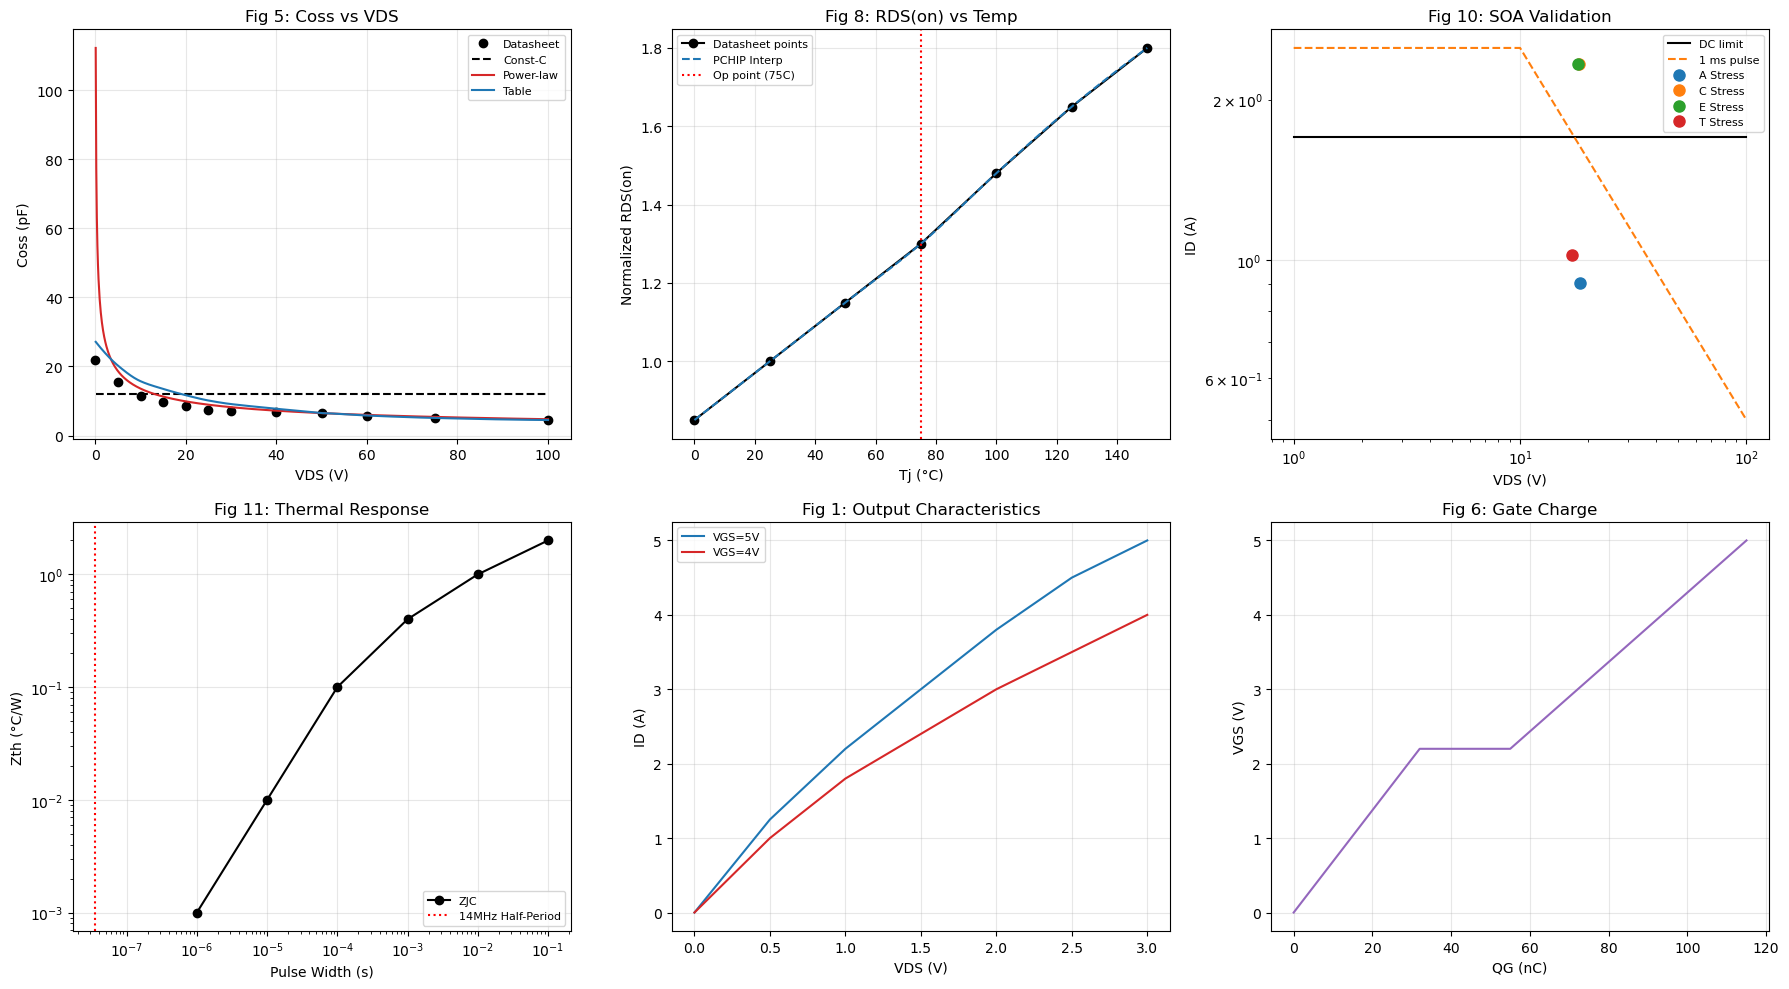


### DYNAMIC EVALUATION OF TUNED DESIGN (T)

1) ZVS (V_turnon < 10 mV): PASS (Actual: 0.01 mV)
2) Current (i_sw_pk < 1.7 A): PASS (Actual: 1.022 A)
3) Power (|Pout - 1.65| < 50 mW): PASS (Actual: 1651.6 mW)
4) Bounds: PASS — interior


In [2]:
# =============================================================================
# CONSOLIDATED EPC2037 GaN CLASS-E NOTEBOOK
# All models overlaid in every plot. All diagnostics restored.
# =============================================================================

# =============================================================================
# Layer 1 — Imports, datasheet card, analytical design
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq, minimize
from scipy.interpolate import PchipInterpolator
import pandas as pd
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# --- Specs ---
VDD, POUT_TARGET, F0 = 4.85, 1.65, 14.0e6
W0, T, TH = 2*np.pi*F0, 1/F0, 1/(2*F0)
VDS_MAX, ID_MAX = 100.0, 1.7
RON_25, RON_MAX_25 = 0.400, 0.550
QG, VG = 115e-12, 5.0
PGATE = QG*VG*F0
COSS_50, QOSS_50, COSS_TR = 6.5e-12, 600e-12, 12e-12
COSS_ER, COSS_50_MAX = 9.5e-12, 10e-12
QOSS_50_MAX = 900e-12
EOSS_ER_50 = 0.5*COSS_ER*50**2
QGS, QGD, RG = 32e-12, 25e-12, 0.5
CISS, CRSS = 14e-12, 0.1e-12

# --- Analytical Design ---
a = 2/np.sqrt(np.pi**2 + 4)
phi = np.pi - np.arctan(2/np.pi)
KR, KC = 2*a**2, 2*a**2/np.pi
Ropt_ana = KR*VDD**2/POUT_TARGET
Csh_ideal = KC/(W0*Ropt_ana)

IR_norm = np.sqrt(2/KR)
IDC_norm = a*IR_norm
C_norm = KC/KR
th = np.linspace(0, 2*np.pi, 200001)
vd_norm = np.zeros_like(th)
off = th >= np.pi
vd_norm[off] = (IDC_norm*(th[off]-np.pi) + IR_norm*(np.cos(th[off]+phi)-np.cos(np.pi+phi)))/C_norm
V1 = np.trapezoid(vd_norm*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
KL = (V1/I1).imag/(V1/I1).real
L1_ana = KL*Ropt_ana/W0
L2_ana = 3.0*Ropt_ana/W0
C2_ana = 1/(W0**2*L2_ana)
LT_ana = L1_ana + L2_ana
IDC_sk = POUT_TARGET/VDD
IR_sk = np.sqrt(2*POUT_TARGET/Ropt_ana)

print("ANALYTICAL CLASS-E DESIGN")
print("-"*60)
print(f"KR = {KR:.6f}, KC = {KC:.6f}, KL = {KL:.6f}, phi = {np.degrees(phi):.3f}°")
print(f"Ropt = {Ropt_ana:.4f} Ω, Csh = {Csh_ideal*1e12:.3f} pF, L1 = {L1_ana*1e9:.3f} nH, L2 = {L2_ana*1e9:.3f} nH, C2 = {C2_ana*1e12:.3f} pF")
print(f"IDC Sokal = {IDC_sk*1e3:.3f} mA, IR Sokal = {IR_sk*1e3:.3f} mA, P_gate = {PGATE*1e3:.3f} mW")

# =============================================================================
# Layer 2 — Temperature model + Coss models
# =============================================================================
DS_FIG8_TJ = np.array([0, 25, 50, 75, 100, 125, 150.])
DS_FIG8_RDS_NORM = np.array([0.85, 1.00, 1.15, 1.30, 1.48, 1.65, 1.80])
_rds_curve = PchipInterpolator(DS_FIG8_TJ, DS_FIG8_RDS_NORM, extrapolate=False)
def temperature_factor(Tj): return float(_rds_curve(Tj))
RON_TYP_75 = RON_25 * temperature_factor(75.0)
RON_MAX_75 = RON_MAX_25 * temperature_factor(75.0)

print("\nTEMPERATURE MODEL (Fig 8)")
print("-"*60)
print(f"RON typical @ 75°C = {RON_TYP_75:.4f} Ω, RON maximum @ 75°C = {RON_MAX_75:.4f} Ω")
print(f"Model equiv C_ER = {2*EOSS_ER_50/50**2*1e12:.3f} pF")

DS_FIG5_VDS = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100.])
DS_FIG5_COSS = 1e-12*np.array([22.0, 15.5, 11.5, 9.8, 8.5, 7.5, 7.0, 6.7, 6.5, 5.8, 5.1, 4.5])
DS_FIG5_CRSS = 1e-12*np.array([2.0, 0.7, 0.2, 0.15, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.08, 0.05])
_coss_dig = PchipInterpolator(DS_FIG5_VDS, DS_FIG5_COSS, extrapolate=False)

V_GRID = np.linspace(0, 150, 150001)
C_GRID_RAW = _coss_dig(np.clip(V_GRID, 0, 100))
Q_GRID_RAW = cumulative_trapezoid(C_GRID_RAW, V_GRID, initial=0)
Q_RAW_50 = Q_GRID_RAW[np.argmin(np.abs(V_GRID-50))]
CAL_A = (QOSS_50 - Q_RAW_50)/25.0
C_GRID = C_GRID_RAW.copy()
C_GRID[V_GRID <= 50] += CAL_A*(1 - V_GRID[V_GRID <= 50]/50)
Q_GRID = cumulative_trapezoid(C_GRID, V_GRID, initial=0)
E_GRID = cumulative_trapezoid(V_GRID*C_GRID, V_GRID, initial=0)

_coss_tab, _qoss_tab, _eoss_tab = PchipInterpolator(V_GRID, C_GRID), PchipInterpolator(V_GRID, Q_GRID), PchipInterpolator(V_GRID, E_GRID)
M_PL = COSS_50*50/QOSS_50

def coss_const(v): return np.full_like(np.asarray(v, float), COSS_TR)
def qoss_const(v): return COSS_TR*np.abs(np.asarray(v, float))
def eoss_const(v): return 0.5*COSS_TR*np.asarray(v, float)**2

def coss_pl(v): return M_PL*QOSS_50/50*(np.maximum(np.abs(np.asarray(v, float)), 1e-12)/50)**(M_PL-1)
def qoss_pl(v): return QOSS_50*(np.abs(np.asarray(v, float))/50)**M_PL
def eoss_pl(v): return M_PL/(M_PL+1)*QOSS_50*50*(np.abs(np.asarray(v, float))/50)**(M_PL+1)

def coss_tab(v): return _coss_tab(np.clip(np.abs(v), 0, 150))
def qoss_tab(v): return np.sign(v)*_qoss_tab(np.abs(v))
def eoss_tab(v): return _eoss_tab(np.abs(v))

# =============================================================================
# Layer 3 — Simulation engine
# =============================================================================
class DeviceModel:
    def __init__(self, name, coss_f, qoss_f, eoss_f, Cext, Ron, kind="nonlin"):
        self.name = name; self.coss_f, self.qoss_f, self.eoss_f = coss_f, qoss_f, eoss_f
        self.Cext, self.Ron, self.kind = float(Cext), float(Ron), kind
        self._vg = np.linspace(0, 150, 150001)
        self._qg = self.Cext*self._vg + np.asarray(self.qoss_f(self._vg), float)
    def v_from_q(self, q):
        q = float(q)
        if abs(q) < 1e-30: return 0.0
        return np.sign(q)*float(np.interp(abs(q), self._qg, self._vg))
    def e_total(self, v): return 0.5*self.Cext*np.asarray(v, float)**2 + np.asarray(self.eoss_f(v), float)

def cycle_const(IDC, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=500, samples=1000):
    def f_on(t, y):
        iL, vC2 = y
        return [(Ron*(IDC-iL) - vC2 - Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        vD, iL, vC2 = y
        return [(IDC-iL)/Csh_val, (vD-vC2-Ropt_val*iL)/LT_val, iL/C2_val]
    iL, vC2 = 0.0, 0.0
    for _ in range(warmup):
        s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13)
        iL, vC2 = s1.y[0, -1], s1.y[1, -1]
        s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL), iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
        iL, vC2 = s2.y[1, -1], s2.y[2, -1]
    s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
    iL_on, vC2_on = s1.y[0, -1], s1.y[1, -1]
    s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL_on), iL_on, vC2_on], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
    t_on, t_off = np.linspace(0, TH, samples+1), np.linspace(0, TH, samples+1)
    y_on, y_off = s1.sol(t_on), s2.sol(t_off)
    t = np.concatenate([t_on, TH+t_off[1:]])
    vD = np.concatenate([Ron*(IDC-y_on[0]) if Ron > 0 else np.zeros_like(t_on), y_off[0][1:]])
    iL_f = np.concatenate([y_on[0], y_off[1][1:]])
    i_sw = np.concatenate([IDC-y_on[0], np.zeros_like(y_off[1][1:])])
    
    q = Csh_val * vD
    coss = np.full_like(vD, COSS_TR)
    
    return {"t": t, "v_D": vD, "i_L": iL_f, "i_sw": i_sw, "q": q, "Coss": coss, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": vD.max(), "v_min": vD.min(), "v_turnon": float(s2.sol(TH)[0]), 
            "i_turnon": float(s2.sol(TH)[1]), "periodic_error": 0.0}

def cycle_nonlin(IDC, dev, LT_val, C2_val, Ropt_val, warmup=300, samples=1200):
    def f_on(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL-vD/dev.Ron, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    y = np.zeros(3); err = 0.0
    for _ in range(warmup):
        s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12)
        s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12)
        yn = s2.y[:, -1]; err = np.max(np.abs(yn-y)); y = yn
        if err < 1e-10: break
    s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    t1, t2 = np.linspace(0, TH, samples, endpoint=False), np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)
    q = np.r_[y1[0], y2[0]]; iL = np.r_[y1[1], y2[1]]; v2 = np.r_[y1[2], y2[2]]
    t = np.r_[t1, TH+t2]; vD = np.array([dev.v_from_q(z) for z in q]); iSW = np.r_[vD[:samples]/dev.Ron, np.zeros(samples)]
    coss_wave = np.array([dev.coss_f(v) for v in vD])
    return {"t": t, "q": q, "v_D": vD, "i_L": iL, "i_sw": iSW, "Coss": coss_wave, "v2": v2, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": np.max(vD), "v_min": np.min(vD), "v_turnon": float(dev.v_from_q(s2.y[0, -1])),
            "i_turnon": float(s2.y[1, -1]), "periodic_error": err}

def solve_const(Ron, LT_val, C2_val, Ropt_val, Csh_val):
    def resid(I): return cycle_const(I, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=200)["v_avg"] - VDD
    I = brentq(resid, 0.7*IDC_sk, 1.3*IDC_sk, xtol=1e-7)
    return cycle_const(I, Ron, LT_val, C2_val, Ropt_val, Csh_val, warmup=500), I

def solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=200, samples=600):
    def resid(I): return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup, samples=samples)["v_avg"] - VDD
    I = brentq(resid, 0.05*POUT_TARGET/VDD, 3.0*POUT_TARGET/VDD, xtol=1e-8)
    return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup*2, samples=samples*2), I

# =============================================================================
# Layer 4 — Baseline runs (A, C, E) + Tuned (T)
# =============================================================================
def run_point(kind, Ron, label, LT_val=LT_ana, C2_val=C2_ana, Ropt_val=Ropt_ana, Cext=None):
    if kind == "const":
        Cext_val = Cext if Cext is not None else Csh_ideal - COSS_TR
        dev = DeviceModel(label, coss_const, qoss_const, eoss_const, Cext_val, Ron, kind="const")
        h, I = solve_const(Ron, LT_val, C2_val, Ropt_val, Cext_val + COSS_TR)
        P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
        P_Ron = Ron*np.trapezoid(h["i_sw"]**2, h["t"])/T
        P_ZVS = 0.5*(Cext_val + COSS_TR)*h["v_turnon"]**2*F0
        P_src = VDD*I
        balance = P_src - P_load - P_Ron - P_ZVS
        E_turn = 0.5*(Cext_val + COSS_TR)*h["v_turnon"]**2
        Ecap = 0.5*(Cext_val + COSS_TR)*h["v_D"]**2
    else:
        Cext_val = Cext if Cext is not None else Csh_ideal - COSS_50
        qf, ef, cf = (qoss_pl, eoss_pl, coss_pl) if kind == "pl" else (qoss_tab, eoss_tab, coss_tab)
        dev = DeviceModel(label, cf, qf, ef, Cext_val, Ron, kind="nonlin")
        h, I = solve_nonlin(dev, LT_val, C2_val, Ropt_val)
        P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
        P_Ron = Ron*np.trapezoid(h["i_sw"]**2, h["t"])/T
        P_src = np.trapezoid(h["v_D"]*I, h["t"])/T
        P_ZVS = 0.0
        balance = P_src - P_load - P_Ron
        E_turn = float(dev.e_total(h["v_turnon"]))
        Ecap = dev.e_total(h["v_D"])
    return {
        "h": h, "I": I, "P_load": P_load, "P_Ron": P_Ron, "P_ZVS": P_ZVS, "P_src": P_src,
        "P_in": VDD*I, "balance": balance, "E_turn": E_turn, "E_cap_avg": np.trapezoid(Ecap, h["t"])/T,
        "E_cap_delta": Ecap[-1] - Ecap[0], "eta_drain": P_load/(VDD*I), "eta_system": P_load/(VDD*I + PGATE),
        "dev": dev, "LT_used": LT_val, "C2_used": C2_val, "Ropt_used": Ropt_val, "Cext_used": Cext_val,
    }

res = {}
print("\nRunning baseline cases A, C, E...")
res["A"] = run_point("const", RON_25, "A: Const-C 25C")
res["C"] = run_point("pl", RON_25, "C: Power-law 25C")
res["E"] = run_point("tab", RON_25, "E: Table 25C")

print("\nRunning SLSQP optimization for Tuned case (T)...")
cache = {}
def eval_design(x):
    key = tuple(np.round(x, 5))
    if key in cache: return cache[key]
    Cext, L1v, L2v, C2v, Roptv = x[0]*1e-12, x[1]*1e-9, x[2]*1e-9, x[3]*1e-12, x[4]
    LTv = L1v + L2v
    dev = DeviceModel("T", coss_tab, qoss_tab, eoss_tab, Cext, RON_25, "nonlin")
    try:
        h, I = solve_nonlin(dev, LTv, C2v, Roptv, warmup=20, samples=100)
        P_load = np.trapezoid(Roptv*h["i_L"]**2, h["t"])/T
        eta = P_load/(VDD*I + PGATE)
        Csh_tot = Cext + dev.coss_f(h["v_turnon"])
        dVdt = (I - h["i_turnon"]) / Csh_tot
        r = (h["v_turnon"], dVdt, P_load, eta, VDD*I, np.max(h["i_sw"]), np.max(h["v_D"]))
    except Exception: r = (10.0, 10.0, 0.0, 0.0, 10.0, 10.0, 10.0)
    cache[key] = r
    return r

def obj(x): return -eval_design(x)[3]
def con_zvs(x): return eval_design(x)[0]
def con_zds(x): return eval_design(x)[1]*1e-8
def con_power(x): return eval_design(x)[2] - POUT_TARGET

x0 = [247.33, 107.73, 280.44, 460.83, Ropt_ana]
bounds = [(100, 500), (50, 250), (150, 450), (200, 900), (3.0, 20.0)]
cons = [{'type':'eq','fun':con_zvs},{'type':'eq','fun':con_zds},{'type':'eq','fun':con_power}]
res_opt = minimize(obj, x0, method='SLSQP', bounds=bounds, constraints=cons, options={'maxiter':300, 'eps':1e-4})

Cext_t, L1_t, L2_t, C2_t, Ropt_t = res_opt.x[0]*1e-12, res_opt.x[1]*1e-9, res_opt.x[2]*1e-9, res_opt.x[3]*1e-12, res_opt.x[4]
res["T"] = run_point("tab", RON_25, "T: Tuned", L1_t + L2_t, C2_t, Ropt_t, Cext_t)
h_T = res["T"]["h"]; I_T = res["T"]["I"]

# =============================================================================
# Layer 5 — Overlaid Waveforms (A, C, E, T)
# =============================================================================
sel = [("A", "Const-C (A)", "k--"), ("C", "Power-law (C)", "C3-"), ("E", "Table (E)", "C1-"), ("T", "Tuned (T)", "C0-")]
fig, ax = plt.subplots(5, 1, figsize=(11, 14), sharex=True)

for key, lab, col in sel:
    h = res[key]["h"]; ph = h["t"]/TH
    ax[0].plot(ph, h["v_D"], col, lw=1.5, label=lab)
    ax[1].plot(ph, h["i_L"], col, lw=1.5, label=lab)
    ax[2].plot(ph, h["i_sw"], col, lw=1.5, label=lab)
    ax[3].plot(ph, h["q"]*1e12, col, lw=1.5, label=lab)
    ax[4].plot(ph, h["Coss"]*1e12, col, lw=1.5, label=lab)

ax[0].axhline(VDD, color="gray", ls=":", label="VDD"); ax[0].axhline(VDS_MAX, color="red", ls=":", alpha=0.5, label="VDS limit")
ax[0].set_ylabel("VDS (V)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[0].set_title("Drain Voltage (Notice ZVS for Tuned)")

ax[1].set_ylabel("Load Current (A)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[2].axhline(ID_MAX, color="red", ls=":", alpha=0.6, label="ID limit 1.7A")
ax[2].set_ylabel("Switch Current (A)"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
ax[2].set_title("Switch Current (Notice 2.3A spike in untuned vs <1A Tuned)")

ax[3].set_ylabel("Drain Charge (pC)"); ax[3].legend(fontsize=8); ax[3].grid(alpha=0.3)
ax[4].set_ylabel("Coss (pF)"); ax[4].set_xlabel("Phase (half-cycle units)"); ax[4].legend(fontsize=8); ax[4].grid(alpha=0.3)

fig.suptitle("Time-Domain Waveforms: All Models Overlaid (25°C)")
plt.tight_layout(); plt.show()

# =============================================================================
# Layer 6 — Overlaid Power & Energy Diagnostics (A, C, E, T)
# =============================================================================
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for key, lab, col in sel:
    h = res[key]["h"]; ph = h["t"]/TH
    dev = res[key]["dev"]; I = res[key]["I"]; Ropt_v = res[key]["Ropt_used"]
    
    P_src = I*h["v_D"]
    P_sw = dev.Ron*h["i_sw"]**2
    P_load = Ropt_v*h["i_L"]**2
    E_cap = dev.e_total(h["v_D"]) if dev.kind != "const" else 0.5*(res[key]["Cext_used"] + COSS_TR)*h["v_D"]**2
    
    ax[0].plot(ph, P_src, col, lw=1.2, label=f"{lab} P_src")
    ax[0].plot(ph, P_sw, col, lw=1.2, ls="--", label=f"{lab} P_sw")
    ax[0].plot(ph, P_load, col, lw=1.2, ls=":", label=f"{lab} P_load")
    
    ax[1].plot(ph, E_cap*1e9, col, lw=1.5, label=lab)
    
    ax[2].plot(ph, P_src - P_sw - P_load, col, lw=1.5, label=lab)

ax[0].set_ylabel("Power (W)"); ax[0].legend(fontsize=7, ncol=3); ax[0].grid(alpha=0.3)
ax[0].set_title("Instantaneous Power Flow")
ax[1].set_ylabel("Stored Energy (nJ)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[2].set_ylabel("Power Residual (W)"); ax[2].set_xlabel("Phase (half-cycle units)"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)

fig.suptitle("Power & Energy Analysis: All Models Overlaid")
plt.tight_layout(); plt.show()

# =============================================================================
# Layer 7 — Sokal Comparison & Full Diagnostics Table
# =============================================================================
print("\n### SOKAL vs SIMULATED (Case A)")
print("-"*80)
print(f"{'Metric':<25} | {'Ideal Sokal':>12} | {'Simulated (A)':>15}")
print("-"*80)
print(f"{'Peak drain voltage (V)':<25} | {17.276:>12.3f} | {res['A']['h']['v_peak']:>15.3f}")
print(f"{'Drain voltage @ turn-on':<25} | {0.0:>12.3f} | {res['A']['h']['v_turnon']:>15.3f}")
print(f"{'Peak load current (A)':<25} | {IR_sk:>12.3f} | {np.max(res['A']['h']['i_L']):>15.3f}")
print(f"{'Load current @ turn-on':<25} | {IR_sk*np.sin(phi):>12.3f} | {res['A']['h']['i_turnon']:>15.3f}")

summary = pd.DataFrame([
    {
        "Tag": k, "Model": sel[i][1],
        "Ron (Ω)": res[k]["dev"].Ron,
        "Cext (pF)": res[k]["Cext_used"]*1e12,
        "Ropt (Ω)": res[k]["Ropt_used"],
        "Vturn_on (V)": res[k]["h"]["v_turnon"],
        "i_sw_pk (A)": np.max(res[k]["h"]["i_sw"]),
        "P_load (mW)": res[k]["P_load"]*1e3,
        "P_Ron (mW)": res[k]["P_Ron"]*1e3,
        "P_ZVS (mW)": res[k]["P_ZVS"]*1e3,
        "P_gate (mW)": PGATE*1e3,
        "P_in (mW)": res[k]["P_in"]*1e3,
        "Pout_err (mW)": (res[k]["P_load"] - POUT_TARGET)*1e3,
        "η_sys (%)": res[k]["eta_system"]*100,
        "bal (mW)": res[k]["balance"]*1e3,
        "E_turn (nJ)": res[k]["E_turn"]*1e9,
    } for i, k in enumerate(["A","C","E","T"])
])
print("\n### FULL DIAGNOSTICS TABLE (ALL VARIANTS)\n")
print(summary.round(3).to_string(index=False))

# =============================================================================
# Layer 8 — Datasheet Validation Plots
# =============================================================================
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
Vp = np.linspace(0.1, 100, 800)

ax[0,0].plot(DS_FIG5_VDS, DS_FIG5_COSS*1e12, "ko", label="Datasheet")
ax[0,0].plot(Vp, coss_const(Vp)*1e12, "k--", label="Const-C")
ax[0,0].plot(Vp, coss_pl(Vp)*1e12, "C3-", label="Power-law")
ax[0,0].plot(Vp, coss_tab(Vp)*1e12, "C0-", label="Table")
ax[0,0].set(xlabel="VDS (V)", ylabel="Coss (pF)", title="Fig 5: Coss vs VDS"); ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=0.3)

Tj = np.linspace(0, 150, 100)
ax[0,1].plot(DS_FIG8_TJ, DS_FIG8_RDS_NORM, "ko-", label="Datasheet points")
ax[0,1].plot(Tj, _rds_curve(Tj), "C0--", label="PCHIP Interp")
ax[0,1].axvline(75, color="red", ls=":", label="Op point (75C)")
ax[0,1].set(xlabel="Tj (°C)", ylabel="Normalized RDS(on)", title="Fig 8: RDS(on) vs Temp"); ax[0,1].legend(fontsize=8); ax[0,1].grid(alpha=0.3)

DS_FIG10_VDS = np.array([1, 10, 100])
DS_FIG10_ID_1MS = np.array([2.5, 2.5, 0.5])
ax[0,2].loglog(DS_FIG10_VDS, [1.7, 1.7, 1.7], "k-", label="DC limit")
ax[0,2].loglog(DS_FIG10_VDS, DS_FIG10_ID_1MS, "C1--", label="1 ms pulse")
for k in ["A", "C", "E", "T"]:
    ax[0,2].plot(res[k]["h"]["v_peak"], np.max(res[k]["h"]["i_sw"]), "o", markersize=8, label=f"{k} Stress")
ax[0,2].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 10: SOA Validation"); ax[0,2].legend(fontsize=8); ax[0,2].grid(alpha=0.3)

DS_FIG11_T = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1])
DS_FIG11_ZJC = np.array([0.001, 0.01, 0.1, 0.4, 1.0, 2.0])
ax[1,0].loglog(DS_FIG11_T, DS_FIG11_ZJC, "ko-", label="ZJC")
ax[1,0].axvline(T/2, color="red", ls=":", label="14MHz Half-Period")
ax[1,0].set(xlabel="Pulse Width (s)", ylabel="Zth (°C/W)", title="Fig 11: Thermal Response"); ax[1,0].legend(fontsize=8); ax[1,0].grid(alpha=0.3)

DS_FIG1_VDS = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
ax[1,1].plot(DS_FIG1_VDS, [0, 1.25, 2.2, 3.0, 3.8, 4.5, 5.0], "C0-", label="VGS=5V")
ax[1,1].plot(DS_FIG1_VDS, [0, 1.0, 1.8, 2.4, 3.0, 3.5, 4.0], "C3-", label="VGS=4V")
ax[1,1].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 1: Output Characteristics"); ax[1,1].legend(fontsize=8); ax[1,1].grid(alpha=0.3)

DS_FIG6_QG = np.array([0, 0.032, 0.055, 0.115])
DS_FIG6_VGS = np.array([0, 2.2, 2.2, 5.0])
ax[1,2].plot(DS_FIG6_QG*1e3, DS_FIG6_VGS, "C4-")
ax[1,2].set(xlabel="QG (nC)", ylabel="VGS (V)", title="Fig 6: Gate Charge"); ax[1,2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

# =============================================================================
# Layer 9 — Dynamic Evaluation
# =============================================================================
print("\n### DYNAMIC EVALUATION OF TUNED DESIGN (T)\n")
zvs_ok = abs(h_T["v_turnon"]) < 0.01
stress_ok = np.max(h_T["i_sw"]) < ID_MAX
power_ok = abs(res["T"]["P_load"] - POUT_TARGET) < 0.05
hit_bounds = [np.isclose(val, b[0], rtol=1e-3) or np.isclose(val, b[1], rtol=1e-3) for val, b in zip(res_opt.x, bounds)]

print(f"1) ZVS (V_turnon < 10 mV): {'PASS' if zvs_ok else 'FAIL'} (Actual: {h_T['v_turnon']*1e3:.2f} mV)")
print(f"2) Current (i_sw_pk < 1.7 A): {'PASS' if stress_ok else 'FAIL'} (Actual: {np.max(h_T['i_sw']):.3f} A)")
print(f"3) Power (|Pout - 1.65| < 50 mW): {'PASS' if power_ok else 'FAIL'} (Actual: {res['T']['P_load']*1e3:.1f} mW)")
print(f"4) Bounds: {'WARNING — hit boundary' if any(hit_bounds) else 'PASS — interior'}")